In [1]:
# Standard library modules needed for setup
import os, sys, subprocess, importlib.util
# Install a package only when Python cannot find it
def ensure_package(module_name, pip_name=None):
    # Check if the module is already available
    if importlib.util.find_spec(module_name) is None:
        # Quiet install; check=False keeps the notebook running even if pip only warns
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module_name], check=False)
# Transformers loads the code language models
ensure_package("transformers")
# Accelerate helps place models on the GPU
ensure_package("accelerate")
# scikit-learn gives the probing regressors
ensure_package("sklearn", "scikit-learn")
# SciPy gives the exact binomial test
ensure_package("scipy")
# Confirmation
print("Packages are ready.")

Packages are ready.


In [2]:
# General utilities
import ast, re, gc, json, math, time, random, itertools, warnings
# Numerical arrays
import numpy as np
# Tables
import pandas as pd
# Figures
import matplotlib.pyplot as plt
# Model backend
import torch
# Library version check
import transformers
# Tokenizer and causal language model classes
from transformers import AutoTokenizer, AutoModelForCausalLM
# Linear probes with built-in regularisation search
from sklearn.linear_model import RidgeCV
# Cross-validated scoring of probes
from sklearn.model_selection import KFold, cross_val_score
# Exact binomial test for paired comparisons
from scipy.stats import binomtest
# Keep the output readable
warnings.filterwarnings("ignore")
# Global seed for reproducibility
SEED = 7
# Seed Python
random.seed(SEED)
# Seed NumPy
np.random.seed(SEED)
# Seed PyTorch
torch.manual_seed(SEED)
# Use the Colab GPU when available
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# Half precision on GPU, full precision on CPU
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
# Show the device
print("Device:", DEVICE)

Device: cuda


In [3]:
# Code LMs whose tracing behaviour we compare (smaller and larger)
MODELS = {"small": "Qwen/Qwen2.5-Coder-0.5B", "large": "Qwen/Qwen2.5-Coder-1.5B"}
# Model used for probing and activation patching (small keeps it fast on a free GPU)
MECH_MODEL = "small"
# Number of variables in a program
N_VARS_GRID = [2, 3, 4, 5]
# Number of times the queried variable is re-assigned
N_REBIND_GRID = [0, 1, 2, 3, 4]
# Kinds of re-assignment (a few are classic "atoms of confusion")
PATTERNS = ["plain", "augmented", "swap", "loop"]
# Programs per design cell
REPS = 5
# Demonstration counts for the few-shot test
SHOT_GRID = [0, 2, 4]
# Number of programs used in the few-shot test (subset keeps run time low)
N_FEWSHOT_ITEMS = 160
# Maximum number of clean/corrupted pairs for activation patching
N_PATCH_PAIRS = 40
# Bootstrap repetitions for confidence intervals
N_BOOT = 1000
# Working folder
WORK_DIR = os.path.abspath("tracing_work")
# Output folder for tables and figures
OUT_DIR = os.path.join(WORK_DIR, "outputs")
# Create folders
os.makedirs(OUT_DIR, exist_ok=True)
# Confirm
print("Outputs will be saved in:", OUT_DIR)

Outputs will be saved in: /content/tracing_work/outputs


In [4]:
# Variable names used in generated programs (i is reserved for loops)
NAMES = ["a", "b", "c", "d", "x", "y", "z", "n", "m", "k"]
# Build one statement that re-assigns the target variable t using another variable o
def rebind_statement(pattern, t, o, rng):
    # Plain re-assignment with arithmetic or copying
    if pattern == "plain":
        return str(rng.choice([f"{t} = {t} + {o}", f"{t} = {o} - {t}", f"{t} = {o}", f"{t} = {t} - {o}"]))
    # Augmented assignment
    if pattern == "augmented":
        return str(rng.choice([f"{t} += {o}", f"{t} -= {o}"]))
    # Tuple swap: a classic confusing pattern
    if pattern == "swap":
        return f"{t}, {o} = {o}, {t}"
    # A small loop that updates the target several times
    return f"for i in range({int(rng.integers(2, 4))}):\n    {t} = {t} + i"
# Distractor statement that changes a non-target variable
def distractor_statement(o, others, rng):
    # Either add a constant or copy from another non-target variable
    if len(others) > 1 and rng.random() < 0.5:
        src = str(rng.choice([v for v in others if v != o]))
        return f"{o} = {src} + {int(rng.integers(1, 4))}"
    return f"{o} = {o} + {int(rng.integers(1, 4))}"
# Variables read and written by a statement (from its syntax tree)
def reads_writes(stmt, var_set):
    # Parse the statement
    tree = ast.parse(stmt)
    # Collect names in load and store contexts
    loads, stores = set(), set()
    for node in ast.walk(tree):
        if isinstance(node, ast.Name) and node.id in var_set:
            if isinstance(node.ctx, ast.Load):
                loads.add(node.id)
            elif isinstance(node.ctx, ast.Store):
                stores.add(node.id)
    # Augmented assignment also reads its target
    for node in ast.walk(tree):
        if isinstance(node, ast.AugAssign) and isinstance(node.target, ast.Name):
            loads.add(node.target.id)
    return loads, stores
# Generate one program and execute it step by step to get the ground truth
def make_item(rng, n_vars, n_rebind, pattern, item_id):
    # Pick distinct variable names; the first is the queried target
    names = [str(v) for v in rng.choice(NAMES, size=n_vars, replace=False)]
    target, others = names[0], names[1:]
    # Every variable starts with a single-digit value
    init = {v: int(rng.integers(1, 10)) for v in names}
    statements = [f"{v} = {init[v]}" for v in names]
    # Body: target re-assignments plus distractors, shuffled but keeping target order
    body = [("t", rebind_statement(pattern, target, str(rng.choice(others)), rng)) for _ in range(n_rebind)]
    body += [("d", distractor_statement(str(o), others, rng)) for o in rng.choice(others, size=n_vars - 1, replace=True)]
    order = rng.permutation(len(body))
    statements += [body[i][1] for i in order]
    # Execute statements one at a time and log reads and writes
    env, events, history = {}, [], []
    for line_no, stmt in enumerate(statements):
        # Values before the statement
        before = dict(env)
        # Run the statement in an isolated namespace
        exec(stmt, {}, env)
        # Variables read and written
        loads, _ = reads_writes(stmt, set(names))
        # Variables whose value changed or were created
        changed = [v for v in names if v in env and (v not in before or before[v] != env[v])]
        events.append({"line": line_no, "reads": sorted(loads), "writes": {v: env[v] for v in changed}})
        # Track every value the target takes
        if target in changed:
            history.append(env[target])
    # Final value is the correct answer
    answer = env[target]
    # Earlier values of the target that differ from the answer are "stale" values
    stale = sorted({h for h in history[:-1] if h != answer})
    # Values of other variables (final and initial) are binding-confusion distractors
    other_vals = sorted(({env[o] for o in others} | {init[o] for o in others}) - {answer} - set(stale))
    # Full code text
    code = "\n".join(statements)
    return {"item_id": item_id, "n_vars": n_vars, "n_rebind": n_rebind, "pattern": pattern if n_rebind > 0 else "none", "target": target, "code": code, "answer": answer, "init_value": init[target], "stale": stale, "other_vals": other_vals, "events": events, "n_lines": len(statements)}
# Answer options scored by the model: truth, stale values, other-variable values and two random numbers
def candidate_values(item, rng):
    # Start with all meaningful values
    cands = {item["answer"]} | set(item["stale"]) | set(item["other_vals"])
    # Add random distractors until there are enough options
    while len(cands) < len(item["stale"]) + len(item["other_vals"]) + 3:
        cands.add(int(rng.integers(-5, 20)))
    return sorted(cands)
# Error type of a predicted value
def error_type(item, value):
    if value == item["answer"]:
        return "correct"
    if value in item["stale"]:
        return "stale"
    if value in item["other_vals"]:
        return "other_variable"
    return "other"
# Prompt that asks for the final value of the target
def make_prompt(item, demos=()):
    # Solved demonstrations in exactly the same format
    prefix = "".join(f"# Python\n{d['code']}\n# Question: what is the value of {d['target']} after this code runs?\n# Answer: {d['target']} = {d['answer']}\n\n" for d in demos)
    return prefix + f"# Python\n{item['code']}\n# Question: what is the value of {item['target']} after this code runs?\n# Answer: {item['target']} ="

In [5]:
# Random generator for the benchmark
rng = np.random.default_rng(SEED)
# Build the main benchmark over the full design
items, iid = [], 0
for n_vars in N_VARS_GRID:
    for n_rebind in N_REBIND_GRID:
        # Without re-assignment the pattern does not matter, so use it once
        for pattern in (PATTERNS if n_rebind > 0 else ["plain"]):
            # Programs without re-assignment get as many repetitions as one rebind level has in total
            for _ in range(REPS * len(PATTERNS) if n_rebind == 0 else REPS):
                items.append(make_item(rng, n_vars, n_rebind, pattern, iid)); iid += 1
# Candidate answers are fixed once so every model sees the same options
for it in items:
    it["candidates"] = candidate_values(it, rng)
# Separate pool for few-shot demonstrations (never used as test items)
demo_rng = np.random.default_rng(SEED + 1)
demo_pool = [make_item(demo_rng, int(demo_rng.choice(N_VARS_GRID)), int(demo_rng.integers(1, 4)), str(demo_rng.choice(PATTERNS)), 10000 + j) for j in range(40)]
# Table view of the benchmark
bench = pd.DataFrame([{k: v for k, v in it.items() if k not in ("events",)} for it in items])
# Save it so the same items can be used in a classroom quiz later
bench.to_csv(os.path.join(OUT_DIR, "tracing_items.csv"), index=False)
# Summary
print("Benchmark items:", len(items))
print(bench.groupby(["n_rebind", "pattern"]).size().unstack(fill_value=0).to_string())
print("\nExample item:\n" + items[-1]["code"])
print("target:", items[-1]["target"], "| answer:", items[-1]["answer"], "| stale:", items[-1]["stale"], "| other variables:", items[-1]["other_vals"])

Benchmark items: 400
pattern   augmented  loop  none  plain  swap
n_rebind                                    
0                 0     0    80      0     0
1                20    20     0     20    20
2                20    20     0     20    20
3                20    20     0     20    20
4                20    20     0     20    20

Example item:
x = 3
k = 6
y = 4
c = 9
a = 5
for i in range(3):
    x = x + i
for i in range(3):
    x = x + i
y = k + 2
for i in range(3):
    x = x + i
for i in range(3):
    x = x + i
c = c + 3
c = y + 3
y = c + 2
target: x | answer: 15 | stale: [3, 6, 9, 12] | other variables: [4, 5, 11, 13]


In [6]:
# Load a model and tokenizer together
def load_lm(name):
    # Fast tokenizer with character offsets
    tok = AutoTokenizer.from_pretrained(name)
    # Major and minor version of Transformers
    ver = tuple(int(x) for x in re.findall(r"\d+", transformers.__version__)[:2])
    # dtype is the argument name from version 4.56 on, torch_dtype before
    if ver >= (4, 56):
        model = AutoModelForCausalLM.from_pretrained(name, dtype=DTYPE)
    else:
        model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=DTYPE)
    # Device and inference mode
    model = model.to(DEVICE)
    model.eval()
    return {"name": name, "tok": tok, "model": model}
# Free GPU memory used by a model
def free_lm(lm):
    # Drop the reference to the model
    lm["model"] = None
    # Collect garbage and clear the CUDA cache
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
# Tokenize text with offsets
def encode(lm, text):
    return lm["tok"](text, return_tensors="pt", return_offsets_mapping=True, add_special_tokens=False)
# Log-probability (nats) of a target string that follows a context
def continuation_logprob(lm, context, target):
    # Tokenize context and target together
    enc = encode(lm, context + target)
    # Token ids on the device
    ids = enc["input_ids"].to(DEVICE)
    # Character offsets of every token
    offsets = enc["offset_mapping"][0].tolist()
    # Forward pass
    with torch.no_grad():
        logits = lm["model"](input_ids=ids).logits[0].float().cpu().numpy()
    # Stable log-softmax
    logits = logits - logits.max(axis=-1, keepdims=True)
    logp = logits - np.log(np.exp(logits).sum(axis=-1, keepdims=True))
    # Token id list
    id_list = ids[0].cpu().numpy().tolist()
    # Sum log-probabilities of tokens that end inside the target
    total = 0.0
    for i in range(1, len(id_list)):
        if offsets[i][1] > len(context):
            total += float(logp[i - 1, id_list[i]])
    return total
# Choose the most likely answer among the candidates
def predict_value(lm, prompt, cands):
    # Score every candidate written as " <number>"
    scores = [continuation_logprob(lm, prompt, f" {c}") for c in cands]
    # Highest score wins
    return cands[int(np.argmax(scores))], scores
# Confirm helpers are defined
print("Scoring helpers ready.")

Scoring helpers ready.


In [7]:
# Behavioural evaluation of both models on the whole benchmark (no demonstrations)
records = []
# Fixed subset for the few-shot test
fewshot_ids = set(np.random.default_rng(SEED + 2).choice([it["item_id"] for it in items if it["n_rebind"] > 0], size=min(N_FEWSHOT_ITEMS, sum(it["n_rebind"] > 0 for it in items)), replace=False).tolist())
# Demonstrations chosen once per test item so both models see the same ones
demo_choice = {it["item_id"]: list(np.random.default_rng(it["item_id"]).choice(len(demo_pool), size=max(SHOT_GRID), replace=False)) for it in items}
# Loop over models
for key, name in MODELS.items():
    # Load the model
    lm = load_lm(name)
    # Timer
    t0 = time.time()
    # Every item and shot setting
    for it in items:
        for shots in SHOT_GRID:
            # Demonstrations only on the few-shot subset
            if shots > 0 and it["item_id"] not in fewshot_ids:
                continue
            # Demonstrations for this item
            demos = [demo_pool[j] for j in demo_choice[it["item_id"]][:shots]]
            # Predict
            pred, _ = predict_value(lm, make_prompt(it, demos), it["candidates"])
            # Store the outcome
            records.append({"model": key, "item_id": it["item_id"], "shots": shots, "n_vars": it["n_vars"], "n_rebind": it["n_rebind"], "pattern": it["pattern"], "pred": pred, "answer": it["answer"], "outcome": error_type(it, pred)})
    # Report time
    print(key, "done in", round(time.time() - t0, 1), "s")
    # Keep the mechanistic model in memory, free the other one
    if key == MECH_MODEL:
        MECH = lm
    else:
        free_lm(lm)
# Results table
res = pd.DataFrame(records)
res["correct"] = (res["outcome"] == "correct").astype(float)
res["stale_error"] = (res["outcome"] == "stale").astype(float)
res.to_csv(os.path.join(OUT_DIR, "llm_tracing_predictions.csv"), index=False)
print(res[res["shots"] == 0].groupby("model")["outcome"].value_counts(normalize=True).round(3).to_string())

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/117 [00:00<?, ?B/s]

large done in 1335.3 s
model  outcome       
large  stale             0.418
       correct           0.322
       other_variable    0.212
       other             0.048
small  stale             0.530
       correct           0.288
       other_variable    0.152
       other             0.030


model  n_rebind  accuracy  ci_low  ci_high  stale_rate  n
large         0     0.900   0.825    0.962       0.000 80
large         1     0.262   0.175    0.362       0.488 80
large         2     0.175   0.100    0.263       0.500 80
large         3     0.175   0.100    0.262       0.575 80
large         4     0.100   0.038    0.163       0.525 80
small         0     0.962   0.912    1.000       0.000 80
small         1     0.100   0.038    0.175       0.750 80
small         2     0.138   0.075    0.225       0.638 80
small         3     0.138   0.075    0.212       0.625 80
small         4     0.100   0.038    0.175       0.638 80
model   pattern  accuracy  ci_low  ci_high  stale_rate  n
large augmented     0.075   0.025    0.138       0.662 80
large      loop     0.100   0.038    0.175       0.488 80
large      none     0.900   0.825    0.962       0.000 80
large     plain     0.238   0.150    0.338       0.450 80
large      swap     0.300   0.200    0.400       0.488 80
small augmente

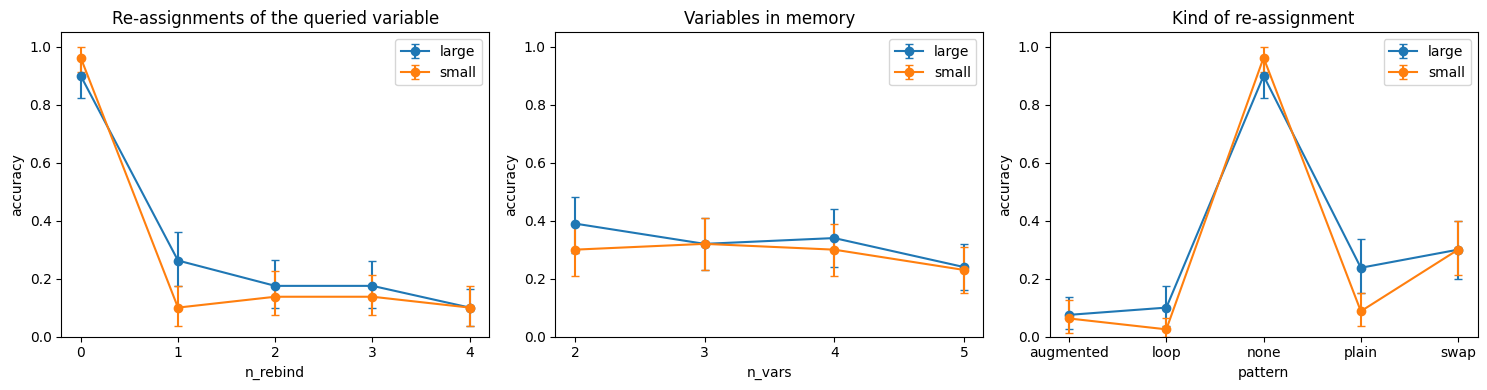

In [8]:
# Bootstrap mean and 95% interval
def boot_ci(values, n_boot=N_BOOT, seed=SEED):
    v = np.asarray(values, dtype=float)
    r = np.random.default_rng(seed)
    means = [r.choice(v, size=len(v), replace=True).mean() for _ in range(n_boot)]
    return float(v.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))
# Accuracy table along one design factor
def by_factor(df, factor):
    rows = []
    for (m, f), t in df.groupby(["model", factor]):
        acc, lo, hi = boot_ci(t["correct"])
        rows.append({"model": m, factor: f, "accuracy": acc, "ci_low": lo, "ci_high": hi, "stale_rate": t["stale_error"].mean(), "n": len(t)})
    return pd.DataFrame(rows)
# Zero-shot results only
zs = res[res["shots"] == 0]
# Tables for the three factors
tab_rebind, tab_vars, tab_pattern = by_factor(zs, "n_rebind"), by_factor(zs, "n_vars"), by_factor(zs, "pattern")
for name, t in [("by_rebind", tab_rebind), ("by_vars", tab_vars), ("by_pattern", tab_pattern)]:
    t.to_csv(os.path.join(OUT_DIR, f"accuracy_{name}.csv"), index=False)
print(tab_rebind.round(3).to_string(index=False))
print(tab_pattern.round(3).to_string(index=False))
# Figure with three panels
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (factor, t) in zip(axes, [("n_rebind", tab_rebind), ("n_vars", tab_vars), ("pattern", tab_pattern)]):
    for m, g in t.groupby("model"):
        xs = np.arange(len(g))
        ax.errorbar(xs, g["accuracy"], yerr=[g["accuracy"] - g["ci_low"], g["ci_high"] - g["accuracy"]], marker="o", capsize=3, label=m)
        ax.set_xticks(xs); ax.set_xticklabels(g[factor].astype(str))
    ax.set_xlabel(factor); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1.05); ax.legend()
axes[0].set_title("Re-assignments of the queried variable"); axes[1].set_title("Variables in memory"); axes[2].set_title("Kind of re-assignment")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig1_llm_tracing.png"), dpi=150); plt.show()

model  shots  accuracy  acc_low  acc_high  stale_rate  stale_low  stale_high   n
large      0     0.200    0.144     0.262       0.506      0.425       0.581 160
large      2     0.238    0.175     0.306       0.381      0.306       0.450 160
large      4     0.250    0.188     0.319       0.344      0.269       0.412 160
small      0     0.138    0.081     0.194       0.662      0.588       0.738 160
small      2     0.131    0.081     0.181       0.494      0.412       0.569 160
small      4     0.100    0.056     0.150       0.525      0.450       0.600 160
small: items lost 14, gained 8 with 4 demonstrations (exact McNemar p = 0.2863)
large: items lost 9, gained 17 with 4 demonstrations (exact McNemar p = 0.1686)


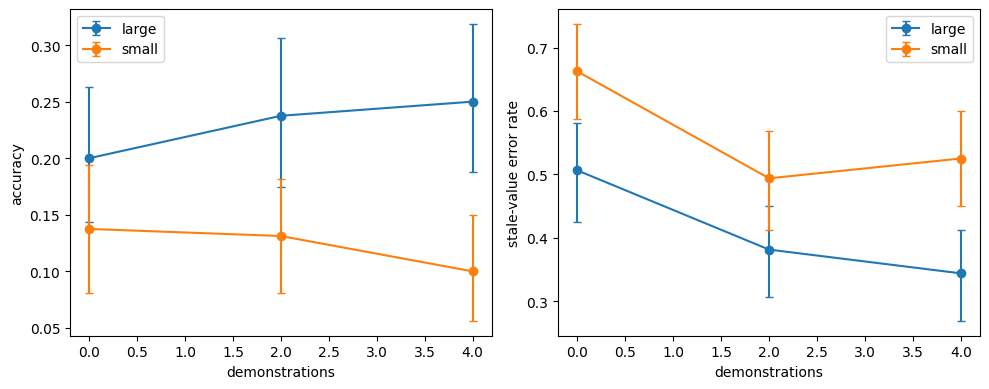

In [9]:
# Few-shot test: do solved demonstrations help or push the model to stale values?
fs = res[res["item_id"].isin(fewshot_ids)]
fs_rows = []
for (m, s), t in fs.groupby(["model", "shots"]):
    acc, lo, hi = boot_ci(t["correct"])
    st, slo, shi = boot_ci(t["stale_error"])
    fs_rows.append({"model": m, "shots": s, "accuracy": acc, "acc_low": lo, "acc_high": hi, "stale_rate": st, "stale_low": slo, "stale_high": shi, "n": len(t)})
fs_table = pd.DataFrame(fs_rows)
fs_table.to_csv(os.path.join(OUT_DIR, "fewshot_effect.csv"), index=False)
print(fs_table.round(3).to_string(index=False))
# Exact McNemar test between 0 and the largest shot count
mcnemar = {}
for m in MODELS:
    wide = fs[fs["model"] == m].pivot_table(index="item_id", columns="shots", values="correct")
    b = int(((wide[0] == 1) & (wide[max(SHOT_GRID)] == 0)).sum())
    c = int(((wide[0] == 0) & (wide[max(SHOT_GRID)] == 1)).sum())
    p = binomtest(min(b, c), b + c, 0.5).pvalue if b + c > 0 else 1.0
    mcnemar[m] = {"lost_with_demos": b, "gained_with_demos": c, "p_value": float(p)}
    print(f"{m}: items lost {b}, gained {c} with {max(SHOT_GRID)} demonstrations (exact McNemar p = {p:.4f})")
# Figure
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for m, t in fs_table.groupby("model"):
    axes[0].errorbar(t["shots"], t["accuracy"], yerr=[t["accuracy"] - t["acc_low"], t["acc_high"] - t["accuracy"]], marker="o", capsize=3, label=m)
    axes[1].errorbar(t["shots"], t["stale_rate"], yerr=[t["stale_rate"] - t["stale_low"], t["stale_high"] - t["stale_rate"]], marker="o", capsize=3, label=m)
axes[0].set_xlabel("demonstrations"); axes[0].set_ylabel("accuracy"); axes[0].legend()
axes[1].set_xlabel("demonstrations"); axes[1].set_ylabel("stale-value error rate"); axes[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig2_fewshot.png"), dpi=150); plt.show()

Probe items: 290
 layer  r2_current_value  r2_initial_value  r2_shuffled_control
     0            -0.033            -0.006               -0.007
     1             0.173            -0.006               -0.008
     2             0.264            -0.009               -0.008
     3             0.270            -0.009               -0.008
     4             0.270             0.005               -0.010
     5             0.321             0.307               -0.009
     6             0.321             0.434               -0.016
     7             0.311             0.431               -0.015
     8             0.335             0.422               -0.020
     9             0.366             0.371               -0.010
    10             0.397             0.534               -0.010
    11             0.379             0.488               -0.010
    12             0.371             0.595               -0.009
    13             0.340             0.603               -0.008
    14             0.26

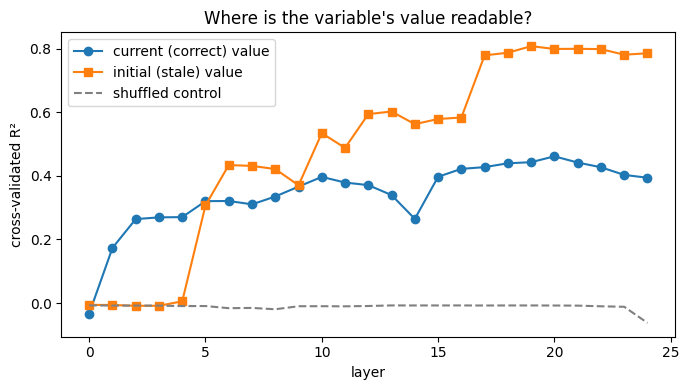

In [10]:
# Hidden states at the last prompt token for every layer
def last_token_states(lm, prompt):
    enc = encode(lm, prompt)
    with torch.no_grad():
        out = lm["model"](input_ids=enc["input_ids"].to(DEVICE), output_hidden_states=True)
    # One vector per layer (index 0 is the embedding layer)
    return np.stack([h[0, -1].float().cpu().numpy() for h in out.hidden_states])
# Items where the initial and final value of the target differ
probe_items = [it for it in items if it["n_rebind"] > 0 and it["init_value"] != it["answer"]]
# Collect states
H = np.stack([last_token_states(MECH, make_prompt(it)) for it in probe_items])
y_final = np.array([it["answer"] for it in probe_items], dtype=float)
y_init = np.array([it["init_value"] for it in probe_items], dtype=float)
# Cross-validated R^2 of a ridge probe per layer
def probe_curve(X3, y):
    kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    return [float(np.mean(cross_val_score(RidgeCV(alphas=np.logspace(-1, 4, 12)), X3[:, l, :], y, cv=kf, scoring="r2"))) for l in range(X3.shape[1])]
# Probes for the current value, the stale initial value, and a shuffled control
r2_final = probe_curve(H, y_final)
r2_init = probe_curve(H, y_init)
r2_shuf = probe_curve(H, np.random.default_rng(SEED).permutation(y_final))
probe_table = pd.DataFrame({"layer": np.arange(H.shape[1]), "r2_current_value": r2_final, "r2_initial_value": r2_init, "r2_shuffled_control": r2_shuf})
probe_table.to_csv(os.path.join(OUT_DIR, "probes_by_layer.csv"), index=False)
print("Probe items:", len(probe_items))
print(probe_table.round(3).to_string(index=False))
# Figure
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(probe_table["layer"], probe_table["r2_current_value"], marker="o", label="current (correct) value")
ax.plot(probe_table["layer"], probe_table["r2_initial_value"], marker="s", label="initial (stale) value")
ax.plot(probe_table["layer"], probe_table["r2_shuffled_control"], linestyle="--", color="grey", label="shuffled control")
ax.set_xlabel("layer"); ax.set_ylabel("cross-validated R²"); ax.set_title("Where is the variable's value readable?"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig3_probes.png"), dpi=150); plt.show()

In [11]:
# Decoder blocks of the model (Qwen2 keeps them in model.model.layers)
def decoder_layers(model):
    if hasattr(model, "model") and hasattr(model.model, "layers"):
        return list(model.model.layers)
    raise AttributeError("Could not find decoder layers on this model")
# Hook that records a layer's output at chosen positions
def make_cache_hook(store, layer_idx, positions):
    def hook(module, inputs, output):
        h = output[0] if isinstance(output, tuple) else output
        for name, p in positions.items():
            store[(layer_idx, name)] = h[:, p, :].clone()
        return None
    return hook
# Hook that overwrites a layer's output at one position with a cached vector
def make_patch_hook(vec, p):
    def hook(module, inputs, output):
        h = output[0] if isinstance(output, tuple) else output
        h = h.clone()
        h[:, p, :] = vec
        return (h,) + tuple(output[1:]) if isinstance(output, tuple) else h
    return hook
# Token index whose character span ends at or just after a character position
def token_at_char(offsets, char_pos):
    for i, (a, b) in enumerate(offsets):
        if b >= char_pos and b > a:
            return i
    return len(offsets) - 1
# Build clean/corrupted pairs that differ only in the target's initial digit
def make_patch_pairs(lm, rng, n_pairs):
    pairs = []
    candidates = [it for it in items if it["pattern"] in ("plain", "augmented") and 1 <= it["n_rebind"] <= 2]
    for it in candidates:
        if len(pairs) >= n_pairs:
            break
        # New initial digit for the corrupted program
        new_init = it["init_value"] % 9 + 1
        corrupt_code = it["code"].replace(f"{it['target']} = {it['init_value']}", f"{it['target']} = {new_init}", 1)
        # Re-run the corrupted program to get its answer
        env = {}
        exec(corrupt_code, {}, env)
        corrupt_answer = env[it["target"]]
        # The two programs must lead to different answers
        if corrupt_answer == it["answer"]:
            continue
        clean_p = make_prompt(it)
        corrupt_p = make_prompt(dict(it, code=corrupt_code))
        ce, ke = encode(lm, clean_p), encode(lm, corrupt_p)
        cid, kid = ce["input_ids"][0].tolist(), ke["input_ids"][0].tolist()
        # Token sequences must align one to one
        if len(cid) != len(kid):
            continue
        diff = [i for i in range(len(cid)) if cid[i] != kid[i]]
        if len(diff) == 0:
            continue
        # Prompt tokens must stay the same when an answer is appended
        ok = all(encode(lm, clean_p + f" {v}")["input_ids"][0].tolist()[:len(cid)] == cid for v in (it["answer"], corrupt_answer))
        if not ok:
            continue
        offsets = ce["offset_mapping"][0].tolist()
        # Character position at the end of the last line that re-assigns the target
        code_start = clean_p.index(it["code"])
        last_line = max(e["line"] for e in it["events"] if it["target"] in e["writes"])
        line_end = code_start + sum(len(l) + 1 for l in it["code"].split("\n")[:last_line + 1]) - 1
        positions = {"initial value": diff[0], "last re-assignment": token_at_char(offsets, line_end), "final token": len(cid) - 1}
        pairs.append({"item": it, "clean_prompt": clean_p, "corrupt_prompt": corrupt_p, "clean_answer": it["answer"], "corrupt_answer": corrupt_answer, "positions": positions})
    return pairs
# Logit difference: how much the model prefers the clean answer over the corrupted one
def logit_diff(lm, prompt, a_clean, a_corrupt):
    return continuation_logprob(lm, prompt, f" {a_clean}") - continuation_logprob(lm, prompt, f" {a_corrupt}")
# Build the pairs
patch_pairs = make_patch_pairs(MECH, rng, N_PATCH_PAIRS)
print("Patching pairs:", len(patch_pairs))

Patching pairs: 40


Pairs used: 20
       initial value  last re-assignment  final token
layer                                                
0              1.004              -0.001       -0.000
1              1.004               0.001       -0.001
2              0.991               0.001       -0.000
3              0.991               0.001       -0.000
4              1.010              -0.002       -0.000
5              1.016               0.001        0.002
6              1.007              -0.001       -0.000
7              0.983               0.001       -0.000
8              0.911              -0.001       -0.000
9              0.910               0.001        0.000
10             0.906               0.003        0.002
11             0.903               0.004        0.003
12             0.901               0.003        0.005
13             0.906               0.006        0.006
14             0.908               0.004        0.011
15             0.911              -0.001        0.015
16           

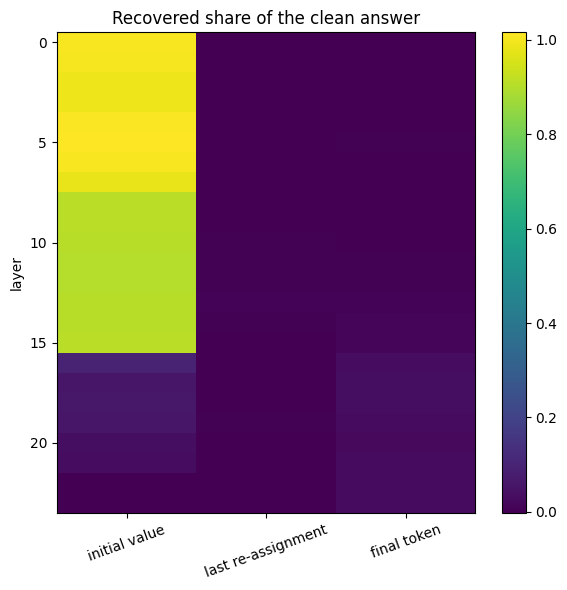

In [12]:
# Activation patching: copy one clean activation into the corrupted run and see how much of the clean answer comes back
layers = decoder_layers(MECH["model"])
pos_names = ["initial value", "last re-assignment", "final token"]
recovery = {name: np.zeros(len(layers)) for name in pos_names}
used = 0
for pr in patch_pairs:
    # Baseline preferences without patching
    ld_clean = logit_diff(MECH, pr["clean_prompt"], pr["clean_answer"], pr["corrupt_answer"])
    ld_corr = logit_diff(MECH, pr["corrupt_prompt"], pr["clean_answer"], pr["corrupt_answer"])
    # Skip pairs the model cannot tell apart
    if ld_clean - ld_corr < 0.5:
        continue
    # Cache clean activations at the three positions in every layer
    store = {}
    handles = [layer.register_forward_hook(make_cache_hook(store, li, pr["positions"])) for li, layer in enumerate(layers)]
    with torch.no_grad():
        MECH["model"](input_ids=encode(MECH, pr["clean_prompt"])["input_ids"].to(DEVICE))
    for h in handles:
        h.remove()
    # Patch one layer and one position at a time
    for li, layer in enumerate(layers):
        for name in pos_names:
            handle = layer.register_forward_hook(make_patch_hook(store[(li, name)], pr["positions"][name]))
            ld_patch = logit_diff(MECH, pr["corrupt_prompt"], pr["clean_answer"], pr["corrupt_answer"])
            handle.remove()
            # Share of the clean preference restored by this single patch
            recovery[name][li] += (ld_patch - ld_corr) / (ld_clean - ld_corr)
    used += 1
# Average over usable pairs
patch_table = pd.DataFrame({name: recovery[name] / max(used, 1) for name in pos_names})
patch_table.index.name = "layer"
patch_table.to_csv(os.path.join(OUT_DIR, "activation_patching.csv"))
print("Pairs used:", used)
print(patch_table.round(3).to_string())
# Heatmap
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(patch_table.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(pos_names))); ax.set_xticklabels(pos_names, rotation=20)
ax.set_ylabel("layer"); ax.set_title("Recovered share of the clean answer")
plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig4_patching.png"), dpi=150); plt.show()
# Release the model
free_lm(MECH)

In [13]:
# ACT-R style memory model of tracing
# Every assignment creates or strengthens a (variable, value) chunk; every read rehearses the variable's current chunk
ACTR = {"decay": 0.5, "noise": 0.4, "threshold": -1.0, "mismatch": 1.5, "line_time": 2.0}
# Outcome probabilities (correct, stale, other) for one item at capacity W, plus an optional cue boost
def actr_probs(item, W, cue_boost=0.0, p=ACTR):
    # Presentation times of every chunk and the latest value of every variable
    pres, latest = {}, {}
    for e in item["events"]:
        t = (e["line"] + 1) * p["line_time"]
        # Reads rehearse the current value of the read variable
        for v in e["reads"]:
            if v in latest:
                pres.setdefault((v, latest[v]), []).append(t)
        # Writes create or strengthen chunks
        for v, val in e["writes"].items():
            pres.setdefault((v, val), []).append(t)
            latest[v] = val
    # Retrieval happens one line after the program ends
    t_q = (item["n_lines"] + 1) * p["line_time"]
    acts, vals = [], []
    for (v, val), ts in pres.items():
        # Base-level activation: frequency and recency with power-law decay
        base = math.log(sum((t_q - t) ** (-p["decay"]) for t in ts))
        # Capacity W spreads activation from the goal cues: the queried variable and "most recent value"
        cue = (W + cue_boost) * ((v == item["target"]) + (v == item["target"] and latest.get(v) == val))
        # Partial matching penalty for chunks of other variables
        pen = 0.0 if v == item["target"] else p["mismatch"]
        acts.append(base + cue - pen); vals.append(val)
    # Boltzmann retrieval with a failure option at the threshold
    temp = p["noise"] * math.sqrt(2)
    a = np.array(acts + [p["threshold"]]) / temp
    pr = np.exp(a - a.max()); pr = pr / pr.sum()
    # Collapse chunk probabilities into outcome classes by value
    out = {"correct": 0.0, "stale": 0.0, "other": float(pr[-1])}
    for val, q in zip(vals, pr[:-1]):
        out["correct" if val == item["answer"] else ("stale" if val in item["stale"] else "other")] += float(q)
    return out
# Grid of capacity values
W_GRID = np.round(np.linspace(0.0, 3.0, 31), 2)
# Pre-compute predictions for every item and capacity
item_by_id = {it["item_id"]: it for it in items}
PRED = {(it["item_id"], w): actr_probs(it, w) for it in items for w in W_GRID}
# Predicted accuracy by number of re-assignments for a few capacities
curve = pd.DataFrame([{"W": w, "n_rebind": it["n_rebind"], "p_correct": PRED[(it["item_id"], w)]["correct"], "p_stale": PRED[(it["item_id"], w)]["stale"]} for it in items for w in [0.3, 0.8, 1.5, 2.5]])
curve_tab = curve.groupby(["W", "n_rebind"])[["p_correct", "p_stale"]].mean().reset_index()
print(curve_tab.pivot(index="n_rebind", columns="W", values="p_correct").round(3).to_string())

W           0.3    0.8    1.5    2.5
n_rebind                            
0         0.507  0.839  0.983  1.000
1         0.407  0.650  0.873  0.976
2         0.381  0.592  0.829  0.965
3         0.318  0.518  0.776  0.951
4         0.326  0.516  0.768  0.948


small: best-fitting capacity W = 0.1 (log-lik -385.2); correlation of predicted and observed accuracy across re-assignment levels = 0.793
large: best-fitting capacity W = 0.1 (log-lik -439.4); correlation of predicted and observed accuracy across re-assignment levels = 0.861


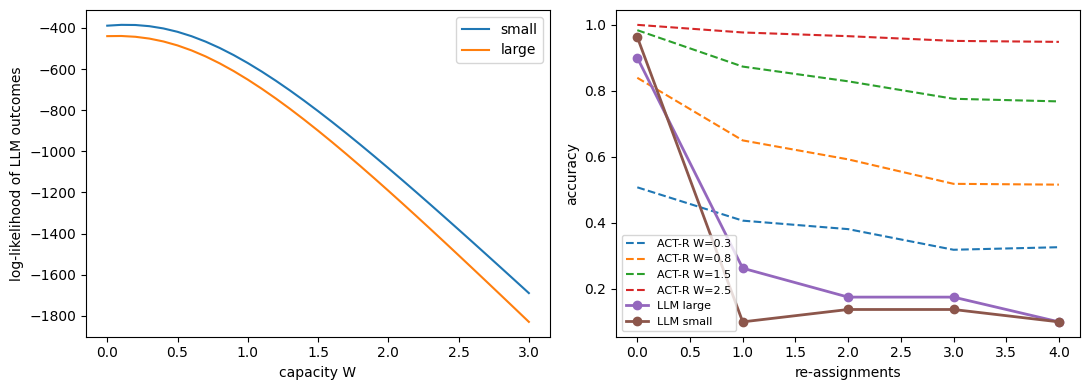

In [14]:
# Which memory capacity best describes each LLM's errors?
def outcome3(o):
    return "other" if o in ("other", "other_variable") else o
fit_rows, ll_curves = [], {}
for m in MODELS:
    t = zs[zs["model"] == m]
    # Log-likelihood of the observed outcomes at every capacity
    ll = [sum(math.log(max(PRED[(i, w)][outcome3(o)], 1e-9)) for i, o in zip(t["item_id"], t["outcome"])) for w in W_GRID]
    ll_curves[m] = ll
    w_best = float(W_GRID[int(np.argmax(ll))])
    # Predicted versus observed accuracy by number of re-assignments at the best capacity
    pred_acc = t.assign(p=[PRED[(i, w_best)]["correct"] for i in t["item_id"]]).groupby("n_rebind")[["p", "correct"]].mean()
    r = float(np.corrcoef(pred_acc["p"], pred_acc["correct"])[0, 1]) if pred_acc["correct"].std() > 0 and pred_acc["p"].std() > 0 else float("nan")
    fit_rows.append({"model": m, "best_W": w_best, "log_lik": float(max(ll)), "corr_by_rebind": r})
    print(f"{m}: best-fitting capacity W = {w_best} (log-lik {max(ll):.1f}); correlation of predicted and observed accuracy across re-assignment levels = {r:.3f}")
fit_table = pd.DataFrame(fit_rows)
fit_table.to_csv(os.path.join(OUT_DIR, "actr_fit_to_llms.csv"), index=False)
# Figure: likelihood over capacity, and model curves
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for m, ll in ll_curves.items():
    axes[0].plot(W_GRID, ll, label=m)
axes[0].set_xlabel("capacity W"); axes[0].set_ylabel("log-likelihood of LLM outcomes"); axes[0].legend()
for w, g in curve_tab.groupby("W"):
    axes[1].plot(g["n_rebind"], g["p_correct"], linestyle="--", label=f"ACT-R W={w}")
for m, g in tab_rebind.groupby("model"):
    axes[1].plot(g["n_rebind"], g["accuracy"], marker="o", linewidth=2, label=f"LLM {m}")
axes[1].set_xlabel("re-assignments"); axes[1].set_ylabel("accuracy"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig5_actr_vs_llm.png"), dpi=150); plt.show()

 K   mae  group_acc  mae_prior_baseline
 1 0.502      0.690               0.621
 3 0.368      0.805               0.621
 5 0.354      0.855               0.621
10 0.292      0.935               0.621


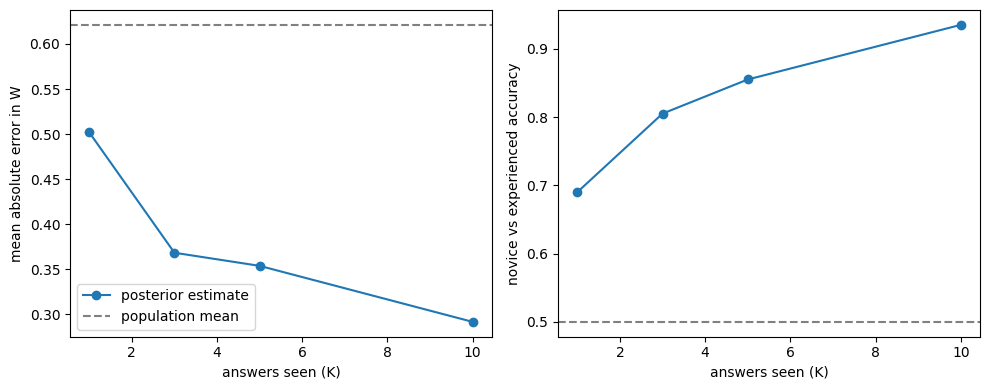

In [15]:
# Simulated students: novices have low capacity, experienced programmers higher capacity
sim_rng = np.random.default_rng(SEED + 3)
N_STUDENTS = 200
students = pd.DataFrame({"student": range(N_STUDENTS), "group": ["novice"] * (N_STUDENTS // 2) + ["experienced"] * (N_STUDENTS - N_STUDENTS // 2)})
students["W"] = np.where(students["group"] == "novice", sim_rng.normal(0.6, 0.2, N_STUDENTS), sim_rng.normal(1.8, 0.3, N_STUDENTS)).clip(0.0, 3.0)
# Items students can see (with at least one re-assignment)
quiz_ids = [it["item_id"] for it in items if it["n_rebind"] > 0]
# Nearest grid value of a capacity
def snap(w):
    return float(W_GRID[int(np.argmin(np.abs(W_GRID - w)))])
# Draw one outcome for a student on an item
def simulate_answer(w, item_id, r):
    pr = PRED[(item_id, snap(w))]
    return r.choice(["correct", "stale", "other"], p=np.array([pr["correct"], pr["stale"], pr["other"]]) / sum(pr.values()))
# Posterior over capacity from a few answers (flat prior on the grid)
def posterior_W(obs):
    ll = np.array([sum(math.log(max(PRED[(i, w)][o], 1e-9)) for i, o in obs) for w in W_GRID])
    post = np.exp(ll - ll.max())
    return post / post.sum()
# Few-shot estimation for K = 1, 3, 5, 10 answers
K_GRID = [1, 3, 5, 10]
est_rows = []
for _, s in students.iterrows():
    # Each student answers 10 random items
    seen = list(sim_rng.choice(quiz_ids, size=max(K_GRID), replace=False))
    obs = [(i, simulate_answer(s["W"], i, sim_rng)) for i in seen]
    for k in K_GRID:
        post = posterior_W(obs[:k])
        w_hat = float((post * W_GRID).sum())
        est_rows.append({"student": s["student"], "group": s["group"], "true_W": s["W"], "K": k, "W_hat": w_hat, "abs_error": abs(w_hat - s["W"]), "pred_group": "novice" if w_hat < 1.2 else "experienced", "accuracy_seen": np.mean([o == "correct" for _, o in obs[:k]])})
est = pd.DataFrame(est_rows)
est["group_correct"] = (est["group"] == est["pred_group"]).astype(float)
# Baseline: always guess the population mean capacity
prior_err = float(np.abs(students["W"] - students["W"].mean()).mean())
est_summary = est.groupby("K").agg(mae=("abs_error", "mean"), group_acc=("group_correct", "mean")).reset_index()
est_summary["mae_prior_baseline"] = prior_err
est_summary.to_csv(os.path.join(OUT_DIR, "fewshot_capacity_estimation.csv"), index=False)
print(est_summary.round(3).to_string(index=False))
# Figure
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(est_summary["K"], est_summary["mae"], marker="o", label="posterior estimate")
axes[0].axhline(prior_err, color="grey", linestyle="--", label="population mean")
axes[0].set_xlabel("answers seen (K)"); axes[0].set_ylabel("mean absolute error in W"); axes[0].legend()
axes[1].plot(est_summary["K"], est_summary["group_acc"], marker="o")
axes[1].axhline(0.5, color="grey", linestyle="--")
axes[1].set_xlabel("answers seen (K)"); axes[1].set_ylabel("novice vs experienced accuracy")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig6_capacity_estimation.png"), dpi=150); plt.show()

                policy  utility  ci_low  ci_high
           always_none    0.669   0.643    0.696
always_recall_reminder    0.778   0.761    0.795
    always_trace_table    0.670   0.670    0.670
          personalised    0.787   0.774    0.801
                oracle    0.813   0.802    0.826

Utility by group:
             always_none  always_recall_reminder  always_trace_table  personalised  oracle
group                                                                                     
experienced        0.856                   0.893                0.67         0.872   0.899
novice             0.454                   0.647                0.67         0.690   0.715


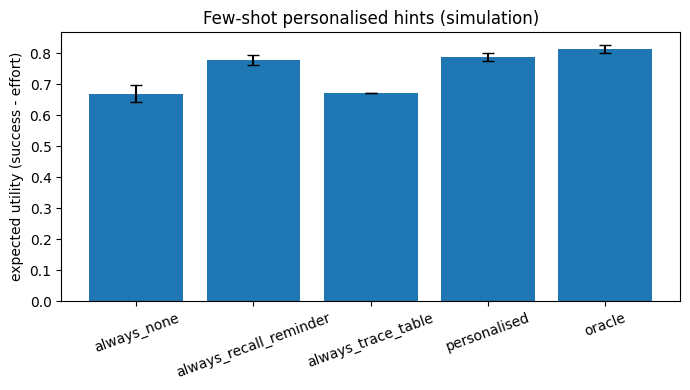

In [16]:
# Hints: a reminder to recall the latest value (boosts the cue) or a full trace table (external memory, costs time)
HINTS = {"none": {"cost": 0.0}, "recall_reminder": {"cost": 0.05, "boost": 0.6}, "trace_table": {"cost": 0.30, "p_correct": 0.97}}
# Expected utility of a hint for a capacity on an item: success probability minus effort cost
def hint_utility(hint, w, item):
    if hint == "trace_table":
        return HINTS[hint]["p_correct"] - HINTS[hint]["cost"]
    boost = HINTS[hint].get("boost", 0.0)
    return actr_probs(item, snap(w), cue_boost=boost)["correct"] - HINTS[hint]["cost"]
# Evaluate policies on held-out items for every simulated student
pol_rows = []
K_POLICY = 5
for _, s in students.sample(n=60, random_state=SEED).iterrows():
    # Five observed answers give the posterior
    seen = list(sim_rng.choice(quiz_ids, size=K_POLICY + 5, replace=False))
    obs = [(i, simulate_answer(s["W"], i, sim_rng)) for i in seen[:K_POLICY]]
    post = posterior_W(obs)
    # Five new items where a hint is chosen
    for i in seen[K_POLICY:]:
        it = item_by_id[i]
        # True utility of each hint for this student
        true_u = {h: hint_utility(h, s["W"], it) for h in HINTS}
        # Personalised: maximise expected utility under the posterior (top grid points for speed)
        top = np.argsort(-post)[:5]
        exp_u = {h: sum(post[j] * hint_utility(h, W_GRID[j], it) for j in top) / post[top].sum() for h in HINTS}
        choice = max(exp_u, key=exp_u.get)
        row = {"student": s["student"], "group": s["group"], "item_id": i, "personalised": true_u[choice], "oracle": max(true_u.values())}
        for h in HINTS:
            row["always_" + h] = true_u[h]
        pol_rows.append(row)
pol = pd.DataFrame(pol_rows)
pol.to_csv(os.path.join(OUT_DIR, "hint_policy_simulation.csv"), index=False)
policy_cols = ["always_none", "always_recall_reminder", "always_trace_table", "personalised", "oracle"]
pol_summary = pd.DataFrame([dict(policy=c, **dict(zip(["utility", "ci_low", "ci_high"], boot_ci(pol[c])))) for c in policy_cols])
pol_summary.to_csv(os.path.join(OUT_DIR, "hint_policy_summary.csv"), index=False)
print(pol_summary.round(3).to_string(index=False))
print("\nUtility by group:")
print(pol.groupby("group")[policy_cols].mean().round(3).to_string())
# Figure
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(pol_summary["policy"], pol_summary["utility"], yerr=[pol_summary["utility"] - pol_summary["ci_low"], pol_summary["ci_high"] - pol_summary["utility"]], capsize=4)
ax.set_ylabel("expected utility (success - effort)"); ax.set_title("Few-shot personalised hints (simulation)")
plt.xticks(rotation=20); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig7_hint_policy.png"), dpi=150); plt.show()

In [17]:
# Optional real classroom data: student_tracing.csv with columns student_id, item_id, outcome (correct / stale / other)
REAL_PATH = os.path.join(WORK_DIR, "student_tracing.csv")
if os.path.exists(REAL_PATH):
    real = pd.read_csv(REAL_PATH)
    # Keep rows that refer to benchmark items and valid outcomes
    real = real[real["item_id"].isin(item_by_id) & real["outcome"].isin(["correct", "stale", "other"])]
    # Capacity estimate per student
    real_rows = []
    for sid, g in real.groupby("student_id"):
        post = posterior_W(list(zip(g["item_id"], g["outcome"])))
        real_rows.append({"student_id": sid, "n_answers": len(g), "W_hat": float((post * W_GRID).sum()), "accuracy": float((g["outcome"] == "correct").mean())})
    real_est = pd.DataFrame(real_rows)
    real_est.to_csv(os.path.join(OUT_DIR, "real_student_capacity.csv"), index=False)
    print(real_est.round(3).to_string(index=False))
else:
    print("No classroom file found; the analysis above uses simulated students only.")

No classroom file found; the analysis above uses simulated students only.


In [18]:
# Headline numbers for the proposal
summary = {
    "n_items": len(items),
    "zero_shot_accuracy": zs.groupby("model")["correct"].mean().round(4).to_dict(),
    "zero_shot_stale_rate": zs.groupby("model")["stale_error"].mean().round(4).to_dict(),
    "accuracy_by_rebind": tab_rebind.round(4).to_dict(orient="records"),
    "fewshot_effect": fs_table.round(4).to_dict(orient="records"),
    "fewshot_mcnemar": mcnemar,
    "probe_best_layer_current_value": int(probe_table["r2_current_value"].idxmax()),
    "probe_best_r2_current_value": round(float(probe_table["r2_current_value"].max()), 4),
    "patching_pairs_used": int(used),
    "patching_peak_layer": {name: int(patch_table[name].idxmax()) for name in pos_names},
    "actr_fit": fit_table.round(4).to_dict(orient="records"),
    "capacity_estimation": est_summary.round(4).to_dict(orient="records"),
    "hint_policy": pol_summary.round(4).to_dict(orient="records"),
}
with open(os.path.join(OUT_DIR, "summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2, default=str)
print("Saved files:")
for f in sorted(os.listdir(OUT_DIR)):
    print(" -", f)

Saved files:
 - accuracy_by_pattern.csv
 - accuracy_by_rebind.csv
 - accuracy_by_vars.csv
 - activation_patching.csv
 - actr_fit_to_llms.csv
 - fewshot_capacity_estimation.csv
 - fewshot_effect.csv
 - fig1_llm_tracing.png
 - fig2_fewshot.png
 - fig3_probes.png
 - fig4_patching.png
 - fig5_actr_vs_llm.png
 - fig6_capacity_estimation.png
 - fig7_hint_policy.png
 - hint_policy_simulation.csv
 - hint_policy_summary.csv
 - llm_tracing_predictions.csv
 - probes_by_layer.csv
 - summary.json
 - tracing_items.csv
